# chapter2.迴歸


In [130]:
batch_n = 100
in_features = 3
out_features = 1
epoch_n = 100
learning_rate = 0.001

In [131]:
import torch

In [132]:
# y = 3x_1 + 5x_2 + 1x_3
x = torch.rand(batch_n, in_features)
x

tensor([[1.3647e-01, 7.6247e-01, 8.1704e-01],
        [1.0380e-01, 3.9415e-01, 8.7608e-01],
        [5.7475e-01, 6.6464e-01, 7.9926e-01],
        [1.4623e-01, 7.0213e-01, 6.0879e-01],
        [4.9102e-01, 2.7191e-01, 2.6016e-01],
        [1.3435e-02, 5.1381e-01, 9.7977e-01],
        [5.1499e-01, 9.3099e-01, 3.8258e-01],
        [3.7340e-01, 3.3935e-02, 5.9775e-01],
        [6.6641e-01, 7.4296e-01, 9.5739e-01],
        [4.1930e-01, 9.9186e-01, 5.7220e-01],
        [2.3118e-01, 3.7194e-01, 7.1568e-02],
        [1.8277e-01, 8.4526e-01, 3.2610e-01],
        [8.3054e-01, 6.4393e-02, 5.9985e-01],
        [8.2604e-02, 5.9501e-01, 2.2473e-01],
        [8.4277e-01, 5.1522e-01, 8.2902e-01],
        [9.1719e-01, 3.7940e-01, 9.6057e-01],
        [6.6744e-01, 2.2116e-01, 2.6459e-01],
        [8.0287e-01, 7.9674e-01, 7.7169e-01],
        [5.2224e-01, 6.5344e-01, 2.0212e-01],
        [2.4130e-01, 2.9295e-01, 2.7225e-01],
        [7.7313e-01, 9.0959e-01, 8.9704e-01],
        [3.1152e-01, 4.0635e-01, 1

In [133]:
c = torch.tensor([[3.0], [5.0], [1.0]])
c

tensor([[3.],
        [5.],
        [1.]])

In [134]:
y = x.mm(c)
y = y.add(torch.rand(batch_n, out_features))
y

tensor([[5.1135],
        [4.0064],
        [6.8079],
        [4.6790],
        [4.0423],
        [3.9885],
        [6.9240],
        [2.4966],
        [7.0885],
        [6.9020],
        [3.0995],
        [5.8737],
        [3.9102],
        [3.8088],
        [6.6000],
        [5.9526],
        [4.1234],
        [7.6614],
        [5.5289],
        [3.2441],
        [8.4322],
        [3.7988],
        [3.0840],
        [7.4972],
        [5.5238],
        [5.3564],
        [3.7444],
        [6.4240],
        [4.3039],
        [7.3892],
        [5.5641],
        [5.2170],
        [5.3180],
        [5.6736],
        [5.1073],
        [3.7173],
        [2.3506],
        [6.1812],
        [6.6257],
        [5.6150],
        [3.6354],
        [4.7666],
        [3.8671],
        [5.7442],
        [5.5812],
        [4.0449],
        [6.0927],
        [3.9376],
        [4.5222],
        [8.0929],
        [4.3258],
        [5.0406],
        [4.1404],
        [2.7640],
        [3.4400],
        [2

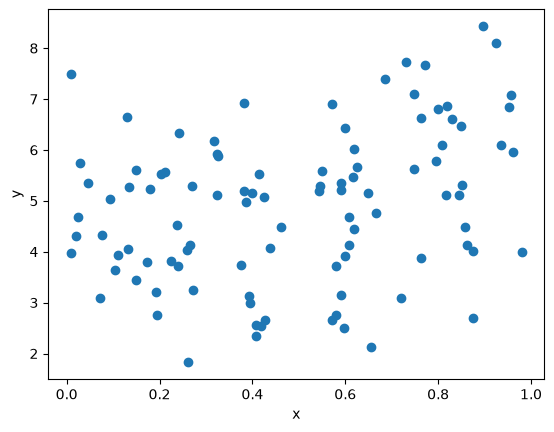

In [135]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(x[:, 2], y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [136]:
w = torch.rand(
    in_features,
    out_features,
)
w

tensor([[0.8047],
        [0.1066],
        [0.9714]])

### 土法煉鋼

In [137]:
for epoch in range(epoch_n):
    y_predict = x.mm(w)
    loss = (y_predict - y).pow(2).sum()
    print("Epoch:{}, Loss:{}".format(epoch, loss))
    
    grand_y_predict = 2 * (y_predict - y)
    grand_w = x.t().mm(grand_y_predict)
    
    w -= learning_rate * grand_w

Epoch:0, Loss:1774.700927734375
Epoch:1, Loss:1288.5196533203125
Epoch:2, Loss:941.50830078125
Epoch:3, Loss:693.6904296875
Epoch:4, Loss:516.575927734375
Epoch:5, Loss:389.8613586425781
Epoch:6, Loss:299.0771789550781
Epoch:7, Loss:233.91107177734375
Epoch:8, Loss:187.0138702392578
Epoch:9, Loss:153.14773559570312
Epoch:10, Loss:128.57969665527344
Epoch:11, Loss:110.64911651611328
Epoch:12, Loss:97.4596176147461
Epoch:13, Loss:87.6594467163086
Epoch:14, Loss:80.2850112915039
Epoch:15, Loss:74.64933776855469
Epoch:16, Loss:70.2625961303711
Epoch:17, Loss:66.77545166015625
Epoch:18, Loss:63.938697814941406
Epoch:19, Loss:61.574485778808594
Epoch:20, Loss:59.55585479736328
Epoch:21, Loss:57.79209518432617
Epoch:22, Loss:56.21833419799805
Epoch:23, Loss:54.788108825683594
Epoch:24, Loss:53.46813201904297
Epoch:25, Loss:52.23445510864258
Epoch:26, Loss:51.069786071777344
Epoch:27, Loss:49.96165466308594
Epoch:28, Loss:48.90095138549805
Epoch:29, Loss:47.88099670410156
Epoch:30, Loss:46.896

In [138]:
w

tensor([[3.2807],
        [4.6916],
        [1.9625]])

### Auto grad

In [139]:
from torch.autograd import Variable

In [140]:
Vx = Variable(x, requires_grad=False)
Vy = Variable(y, requires_grad=False)
Vw = Variable(torch.rand(in_features, out_features), requires_grad=True)

In [141]:
for epoch in range(epoch_n):
    y_predict = Vx.mm(Vw)
    loss = (y_predict - Vy).pow(2).sum()
    print("Epoch:{}, Loss:{}".format(epoch, loss))

    loss.backward()

    Vw.data -= learning_rate * Vw.grad.data
    
    Vw.grad.data.zero_()

Epoch:0, Loss:1999.0892333984375
Epoch:1, Loss:1445.571044921875
Epoch:2, Loss:1050.656494140625
Epoch:3, Loss:768.781494140625
Epoch:4, Loss:567.4755249023438
Epoch:5, Loss:423.5976257324219
Epoch:6, Loss:320.6562805175781
Epoch:7, Loss:246.8985595703125
Epoch:8, Loss:193.9484405517578
Epoch:9, Loss:155.8365936279297
Epoch:10, Loss:128.3086395263672
Epoch:11, Loss:108.33255004882812
Epoch:12, Loss:93.74723815917969
Epoch:13, Loss:83.01239013671875
Epoch:14, Loss:75.0301513671875
Epoch:15, Loss:69.0178451538086
Epoch:16, Loss:64.41752624511719
Epoch:17, Loss:60.83136749267578
Epoch:18, Loss:57.97566604614258
Epoch:19, Loss:55.64802551269531
Epoch:20, Loss:53.704036712646484
Epoch:21, Loss:52.04059982299805
Epoch:22, Loss:50.58405685424805
Epoch:23, Loss:49.281742095947266
Epoch:24, Loss:48.09597396850586
Epoch:25, Loss:46.99970245361328
Epoch:26, Loss:45.9735107421875
Epoch:27, Loss:45.003379821777344
Epoch:28, Loss:44.079193115234375
Epoch:29, Loss:43.19358444213867
Epoch:30, Loss:42.

In [142]:
Vw.data

tensor([[3.2006],
        [4.7728],
        [1.9558]])

### nn.Module


In [143]:
import torch.nn as nn

In [146]:
class Model(nn.Module):
    def __init__(self):
        super(Model, self).__init__()

    def forward(self, x, w):
        y_predict = x.mm(w)
        return y_predict

    def backward(self):
        pass

In [ ]:
model = Model()
Vw = Variable(torch.rand(in_features, out_features), requires_grad=True)